# Машинное обучение, ФКН ВШЭ

# Практическое задание 9. Рекомендательные системы

## Общая информация

**Дата выдачи: 08.10.2026**

**Мягкий дедлайн: 25.10.2026 23:59 MSK**

**Жёсткий дедлайн: 08.11.2026 23:59 MSK**

## Оценивание и штрафы

Каждая из задач имеет определенную «стоимость» (указана в скобках около задачи). Максимально допустимая оценка за работу – **10** баллов за основную часть + **1.5** бонусных.

Сдавать задание после указанного срока сдачи нельзя. При выставлении неполного балла за задание в связи с наличием ошибок на усмотрение проверяющего предусмотрена возможность исправить работу на указанных в ответном письме условиях.

Задание выполняется самостоятельно. «Похожие» решения считаются плагиатом и все задействованные студенты (в том числе те, у кого списали) не могут получить за него больше 0 баллов (подробнее о плагиате см. на странице курса). Если вы нашли решение какого-то из заданий (или его часть) в открытом источнике, необходимо указать ссылку на этот источник в отдельном блоке в конце вашей работы (скорее всего вы будете не единственным, кто это нашел, поэтому чтобы исключить подозрение в плагиате, необходима ссылка на источник).

Неэффективная реализация кода может негативно отразиться на оценке.

## Формат сдачи
Задания сдаются через систему anytask. Посылка должна содержать:

* Ноутбук homework-practice-09-Username.ipynb

Username – ваша фамилия и имя на латинице именно в таком порядке

## О задании

В этой работе мы будем решать задачу рекомендации музыки (звуууук). То есть мы поставим целью получить модель, которая для каждого пользователя будет возвращать набор треков, наиболее похожих на те, что он уже слушал. В первой части мы разберемся с memory-based подходом и моделью со скрытыми переменными. Это не очень мощные методы, но зато они позволяют строить предсказания почти моментально. Затем, во второй части, мы обратим внимание на то, что датасет содержит огромное число треков и воспользуемся результатами уже построенных быстрых моделей для сокращения списка кандидатов до разумного количества. После этого проведем ранжирование среди кандидатов с помощью сильной, но чуть более медленной модели, и отберем самые лучшие варианты. Такой двухэтапный алгоритм построения рекомендаций изображен на картинке.


![](https://i.ibb.co/4RptSVjp/Screenshot-2026-03-23-at-00-29-18.png)

Приступим!

Все шаблоны ниже можно переписывать по своему усмотрению.

In [1]:
from sklearn.preprocessing import LabelEncoder

import pandas as pd
import numpy as np
from tqdm.notebook import tqdm
from typing import Callable, List

import matplotlib.pyplot as plt
import seaborn as sns
import scipy.sparse as scs

In [2]:
ratings = pd.read_csv('music_dataset.csv')
ratings.head()

,userId,trackId
0,0,14
1,0,95
2,0,219
3,0,220
4,0,404


In [3]:
tracks_info = pd.read_csv('tracks_info.csv')
tracks_info.head()

,id,name,artists
0,0,What There Is,['a-ha']
1,1,I'll Play The Blues For You,['Albert King']
2,2,Breaking Up Somebody's Home,['Albert King']
3,3,Imma Be,['Black Eyed Peas']
4,4,Boom Boom Pow,['Black Eyed Peas']


Для оценки качества рекомендаций мы будем использовать метрику $MAP@k$.

$$
MAP@k = \frac{1}{N} \sum_{u = 1}^N AP_u@k
$$
$$
AP_u@k = \frac{1}{\min(k, n_u)} \sum_{i=1}^k r_u(i) p_u@i
$$
$$p_u@k = \dfrac{1}{k}\sum_{j=1}^k r_u(j)$$


*   $N$ - количество пользователей.
*   $n_u$ - число релевантных треков пользователя $u$ на тестовом промежутке.
*   $r_u(i)$ - бинарная величина: относится ли трек на позиции $i$ к релевантным.

**Задание 1 (0.5 балл).** Реализуйте метрику $MAP@k$.

In [4]:
def mapk(relevant: List[List[int]], predicted: List[List[int]], k: int = 20):
    map = []
    for i in range(len(relevant)):
        rel = set(relevant[i])
        preds = predicted[i]
        ap = 0.0
        sm = 0
        for j in range(min(k, len(preds))):
            if preds[j] in rel:
                sm += 1
                ap += sm / (j + 1)
        map.append(ap / min(k, len(rel)))
    return np.mean(np.array(map))

In [5]:
relevant = [
    [1, 7, 6, 2, 8],
    [1, 5, 4, 8],
    [8, 2, 5]
]

pred = [
    [8, 1, 5, 0, 7, 2, 9, 4],
    [0, 1, 8, 5, 3, 4, 7, 9],
    [9, 2, 0, 6, 8, 5, 3, 7]
]

assert round(mapk(relevant, pred, k=5), 4) == 0.4331

Отложим 50 последних строк каждого пользователя, остальные оставим для обучения. В данных нет времени прослушивания, поэтому это не временное разбиение.

Отложенные данные разделим по пользователям: на валидацию, обучение ранкера и финальный тест. В частях 1-2 параметры подбирайте по валидации.

In [6]:
def train_test_split(ratings):
    train_ratings, test_ratings = [], []
    num_test_samples = 50

    for userId, user_data in tqdm(ratings.groupby('userId')):
        train_ratings += [user_data[:-num_test_samples]]

    train_ratings = pd.concat(train_ratings).reset_index(drop=True)
    all_train_items = train_ratings['trackId'].unique()

    # getting train samples
    # we drop all tracks that are not presented it the training samples,
    # because we won't be able to learn representations for them
    for userId, user_data in tqdm(ratings.groupby('userId')):
        test_items = user_data[-num_test_samples:]
        test_items = test_items[np.isin(test_items['trackId'], all_train_items)]
        test_ratings += [test_items]

    test_ratings = pd.concat(test_ratings).reset_index(drop=True)

    return train_ratings, test_ratings

In [7]:
from sklearn.model_selection import train_test_split as split_users

train_ratings, holdout_ratings = train_test_split(ratings)

rank_test_users, valid_users = split_users(
    np.sort(holdout_ratings['userId'].unique()), test_size=0.2, random_state=42
)
rank_train_users, final_test_users = split_users(
    rank_test_users, test_size=0.4, random_state=42
)
rank_train_users = np.sort(rank_train_users)
valid_users = np.sort(valid_users)
final_test_users = np.sort(final_test_users)

rank_train_ratings = holdout_ratings[holdout_ratings['userId'].isin(rank_train_users)].copy()
test_ratings = holdout_ratings[holdout_ratings['userId'].isin(valid_users)].copy()
final_test_ratings = holdout_ratings[holdout_ratings['userId'].isin(final_test_users)].copy()

  0%|          | 0/241 [00:00<?, ?it/s]

  0%|          | 0/241 [00:00<?, ?it/s]

Почистим табличку с информацией о треках и закодируем id треков так, чтобы они соответствовали их порядковому номеру.

In [8]:
redundant_rows = np.where(~np.isin(tracks_info['id'], train_ratings['trackId'].unique()))[0]
tracks_info.drop(redundant_rows, inplace=True)
tracks_info = tracks_info.reset_index(drop=True)

In [9]:
def ids_encoder(ratings):
    users = sorted(ratings['userId'].unique())
    items = sorted(ratings['trackId'].unique())

    # create users and items encoders
    uencoder = LabelEncoder()
    iencoder = LabelEncoder()

    # fit users and items ids to the corresponding encoder
    uencoder.fit(users)
    iencoder.fit(items)

    return uencoder, iencoder

In [10]:
uencoder, iencoder = ids_encoder(train_ratings)
for frame in (train_ratings, test_ratings, rank_train_ratings, final_test_ratings):
    frame['trackId'] = iencoder.transform(frame['trackId'].tolist())
tracks_info['id'] = iencoder.transform(tracks_info['id'].tolist())

In [11]:
train_ratings.head()

,userId,trackId
0,0,14
1,0,95
2,0,219
3,0,220
4,0,404


In [12]:
test_ratings.head()

,userId,trackId
238,9,36055
239,9,36056
240,9,36058
241,9,36063
242,9,36139


Соберем все релевантные треки для каждого пользователя в список.

In [13]:
test_relevant = []
test_users = []
for user_id, user_data in test_ratings.groupby('userId'):
    test_relevant += [user_data['trackId'].tolist()]
    test_users.append(user_id)

final_test_relevant = (
    final_test_ratings.groupby('userId')['trackId'].agg(list)
    .reindex(final_test_users).tolist()
)

**Задание 2 (0.5 балла).** Реализуйте метод `get_test_recommendations` в классе `BaseModel`. Он принимает на вход параметр `k` и возвращает массив из `k` наиболее подходящих треков для каждого пользователя. Не забывайте удалять уже прослушанные треки из рекомендуемых. Аргумент `users` задаёт список пользователей (по умолчанию `test_users`); верните рекомендации в том же порядке.

In [14]:
class BaseModel:
    def __init__(self, ratings: pd.DataFrame):
        self.ratings = ratings
        self.n_users = len(np.unique(self.ratings['userId']))
        self.n_items = len(np.unique(self.ratings['trackId']))

        self.R = np.zeros((self.n_users, self.n_items))
        self.R[self.ratings['userId'], self.ratings['trackId']] = 1.

    def recommend(self, uid: int):
        """
        param uid: int - user's id
        return: [n_items] - vector of recommended items sorted by their scores in descending order
        """
        raise NotImplementedError

    def remove_train_items(self, preds: List[List[int]], k: int):
        """
        param preds: [n_users, n_items] - recommended items for each user
        param k: int
        return: np.array [n_users, k] - recommended items without training examples
        """
        new_preds = np.zeros((len(preds), k), dtype=int)
        for user_id, user_data in self.ratings.groupby('userId'):
            user_preds = preds[user_id]
            new_preds[user_id] = user_preds[~np.isin(user_preds, user_data['trackId'])][:k]

        return new_preds

    def get_test_recommendations(self, k: int, users: List[int] = None):
        test_preds = [np.asarray(self.recommend(uid))
                      for uid in range(self.n_users)]

        test_preds = self.remove_train_items(test_preds, k)

        selected_users = test_users if users is None else users
        return test_preds[selected_users]

### Часть 1. Коллаборативная фильтрация (User2User)

Идея: чтобы выбрать треки, которые понравятся пользователю, можно набрать несколько похожих на него пользователей (соседей) и посмотреть, какие треки они слушают. После этого остается агрегировать треки этих пользователей и выбрать самые популярные. Соответственно, задача состоит из двух частей: выбора функции похожести двух пользователей и способа агрегации.

В качестве функции похожести мы будем использовать меру Жаккара:

$$ s(u, v) = \frac{|I_u \cap I_v|}{|I_u \cup I_v|} $$


Во всех формулах
* $I_u$ - множество треков, прослушанных пользователем $u$.
* $r_{ui}$ - прослушал ли пользователь $u$ трек $i$ (0 или 1).

Множество соседей определим как $$N(u) = \{ v \in U \setminus \{u\} \mid s(u, v) > \alpha\},$$ где $\alpha \, - $ гиперпараметр.



Для агрегации мы будем пользоваться следующей формулой.
$$
\hat{r}_{ui} = \frac{\sum_{v \in N(u)} s(u, v) r_{vi}}{\sum_{v \in N(u)} |s(u, v)|}
$$

**Задание 3 (0.5 балла).** Реализуйте функцию подсчета меры Жаккара.

Функция принимает матрицу оценок и вектор оценок пользователя $u$ и возвращает вектор со значениями похожести пользователя $u$ на всех пользователей. Старайтесь писать оптимизированный код, за неэффективную реализацию оценка может быть снижена.

In [15]:
def jaccard(ratings: np.array, user_vector: np.array) -> np.array:
    intersect = ratings @ user_vector
    union = ratings.sum(axis=1) + user_vector.sum() - intersect
    return intersect / (union + 1e-10)

**Задание 4 (1 балл).** Реализуйте методы `similarity` и `recommend` класса `User2User`. `recommend` возвращает индексы треков, отсортированные в порядке убывания предсказанных оценок. Значение параметра `alpha` можно менять по своему усмотрению так, чтобы оно было разумным.

In [16]:
class User2User(BaseModel):
    def __init__(self, ratings):
        super().__init__(ratings)

        self.similarity_func = jaccard
        self.alpha = 0.02

    def similarity(self, user_vector: np.array):
        """
        user_vector: [n_items]
        """
        return self.similarity_func(self.R, user_vector)

    def recommend(self, uid: int):
        s = self.similarity(self.R[uid])
        neighbors = s > self.alpha
        neighbors[uid] = False
        w = s[neighbors]
        if len(w) == 0:
            scores = np.zeros(self.n_items)
        else:
            scores = w.T @ self.R[neighbors] / w.sum()

        return scores.argsort()[::-1]

**Задание 5 (0.5 балл).** Постройте график зависимости значений $MAP@k$ от разных $k$ при рекомендации на основе меры Жаккара, сравните его с рекомендациями самых популярных треков и случайных. Какой из трех способов рекомендаций оказался лучшим?

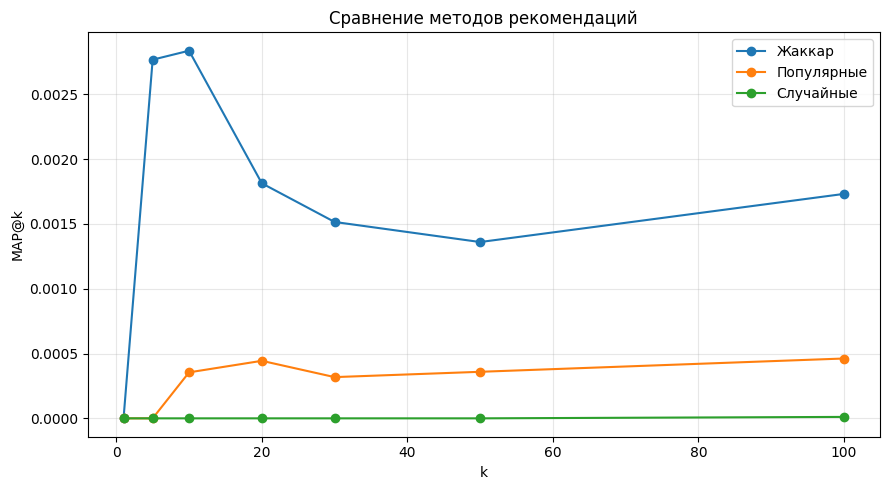

In [17]:
k_values = [1, 5, 10, 20, 30, 50, 100]
max_k = max(k_values)

model = User2User(train_ratings)

jaccard_preds = model.get_test_recommendations(
    k=max_k, users=test_users
)

popular_ranking = np.argsort(-model.R.sum(axis=0))

popular_preds = []
random_preds = []
rng = np.random.default_rng(42)

for uid in test_users:
    unseen_mask = model.R[uid] == 0

    popular_preds.append(
        popular_ranking[unseen_mask[popular_ranking]][:max_k]
    )

    unseen_items = np.flatnonzero(unseen_mask)
    random_preds.append(
        rng.permutation(unseen_items)[:max_k]
    )

predictions = {
    "Жаккар": jaccard_preds,
    "Популярные": popular_preds,
    "Случайные": random_preds,
}

results = pd.DataFrame(
    {
        name: [
            mapk(test_relevant, preds, k=k)
            for k in k_values
        ]
        for name, preds in predictions.items()
    },
    index=pd.Index(k_values, name="k"),
)

ax = results.plot(figsize=(9, 5), marker="o")
ax.set_xlabel("k")
ax.set_ylabel("MAP@k")
ax.set_title("Сравнение методов рекомендаций")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Ответ:** Везде Жаккар

**Бонус (0.5 балла).** Как вы могли заметить, матрица оценок получается очень разреженной, но мы работаем с ней как с обычной, это не дело. Перепишите код так, чтобы все методы могли работать с разреженными матрицами и сравните скорость работы такого подхода с оригинальным.

In [18]:
from scipy.sparse import csr_matrix

class SparseBaseModel:
    def __init__(self, ratings: pd.DataFrame):
        self.ratings = ratings
        self.n_users = len(np.unique(self.ratings['userId']))
        self.n_items = len(np.unique(self.ratings['trackId']))
        self.R = csr_matrix((np.ones(len(ratings)),
                  (ratings['userId'], ratings['trackId'])),
                  shape=(self.n_users, self.n_items))

    def recommend(self, uid: int):
        """
        param uid: int - user's id
        return: [n_items] - vector of recommended items sorted by their scores in descending order
        """
        raise NotImplementedError

    def get_test_recommendations(self, k: int, users: List[int] = None):
        users = test_users if users is None else users
        result = np.empty((len(users), k), dtype=int)

        for i, uid in enumerate(users):
            preds = np.asarray(self.recommend(uid))

            l, r = self.R.indptr[uid], self.R.indptr[uid+1]
            seen = self.R.indices[l:r]

            result[i] = preds[~np.isin(preds, seen)][:k]

        return result

class SparseUser2User(SparseBaseModel):
    def __init__(self, ratings):
        super().__init__(ratings)

        self.alpha = 0.02
        self.user_counts = np.asarray(self.R.sum(axis=1)).ravel()

    def similarity(self, user_vector):
        intersect = (self.R @ user_vector.T).toarray().ravel()
        union = self.user_counts + user_vector.sum() - intersect
        return intersect / (union + 1e-10)

    def recommend(self, uid: int):
        s = self.similarity(self.R.getrow(uid))

        neighbors = s > self.alpha
        neighbors[uid] = False
        w = s[neighbors]

        if len(w) == 0:
            scores = np.zeros(self.n_items)
        else:
            scores = self.R[neighbors].T @ w
            scores = np.asarray(scores).ravel() / w.sum()
        return scores.argsort()[::-1]

In [19]:
from time import perf_counter

t = perf_counter()
model_dence = User2User(train_ratings)
pred_dence = model_dence.get_test_recommendations(
    k=max_k, users=test_users)
t_dence = perf_counter() - t

t = perf_counter()
model_sparse = SparseUser2User(train_ratings)
pred_sparse = model_sparse.get_test_recommendations(
    k=max_k, users=test_users)
t_sparse = perf_counter() - t

assert pred_dence.shape == pred_sparse.shape
assert np.all(pred_dence == pred_sparse)

print("Время плотной матрицы: ", t_dence)
print("Время разреженной матрицы: ", t_sparse)

Время плотной матрицы:  9.678516470999966
Время разреженной матрицы:  0.37614251200000126


**Ответ:** Почти в 30 раз эффективней

Мы можем посмотреть глазами, насколько хорошо модель рекомендует треки. Для этого сравним уже прослушанные треки с рекомендованными и релевантными для случайного пользователя. Хорошо ли у вас получилось?

In [20]:
user_id = np.random.choice(test_users)

In [21]:
listened_tracks = train_ratings[train_ratings.userId == user_id].trackId[:15]

print('Already listened tracks:')

tracks_info.loc[listened_tracks][['name', 'artists']]

Already listened tracks:


,name,artists
3,Imma Be,['Black Eyed Peas']
63,When I Grow Up,['The Pussycat Dolls']
65,Jai Ho! (You Are My Destiny),"['A.R.Rahman', 'The Pussycat Dolls', 'Nicole S..."
103,Right Now (Na Na Na),['Akon']
113,Just A Lil Bit,['50 Cent']
134,Need A Boss,"['Shareefa', 'Ludacris']"
213,Cuidar Nuestro Amor,['David Bisbal']
243,P.I.M.P.,['50 Cent']
277,Wait A Minute,"['The Pussycat Dolls', 'Timbaland']"
281,London Bridge,['Fergie']


In [22]:
preds = model.get_test_recommendations(15)

print('Predicted tracks:')

tracks_info.loc[preds[test_users.index(user_id)]][['name', 'artists']]

Predicted tracks:


,name,artists
52701,Прятки,['HammAli & Navai']
2814,Numb,['Linkin Park']
64683,I WANNA BE YOUR SLAVE,['Måneskin']
35064,Thunder,['Imagine Dragons']
8263,Shape Of My Heart,['Sting']
62418,Снова я напиваюсь,['SLAVA MARLOW']
51525,Прочь,"['TERNOVOY', 'AMCHI']"
59685,X.O,"['Andro', 'The Limba']"
53671,2 типа людей,['Макс Корж']
59229,Мальчик на девятке,['DEAD BLONDE']


In [23]:
test_tracks = test_ratings[test_ratings.userId == user_id].trackId[:15]

print('Validation tracks:')

tracks_info.loc[test_tracks][['name', 'artists']]

Validation tracks:


,name,artists
67163,Солнце Монако,['Люся Чеботина']
67178,МАЛИНОВАЯ ЛАДА,['GAYAZOV$ BROTHER$']
67179,Космос,['Ёлка']
67186,ЧЕ ЗА ЛЕВ ЭТОТ ТИГР,['Gazan']
67206,Потеряли пацана,['Tanir & Tyomcha']
67210,Как дети,['ERSHOV']
67213,Танцевали до утра,['Лёша Свик']
67214,Я так люблю тебя,['Artik & Asti']
67231,Оставаться человеком,['Анет Сай']
67251,Ты должна рядом быть,"['Мари Краймбрери', 'MOT']"


Я не шарю в рекомендованных треках, мб ассист шарит

### Часть 2. Модель со скрытыми переменными: ALS

В этой части мы пощупаем метод рекомендаций со скрытыми переменными.
Идея: будем предсказывать оценки по формуле
$$
\hat{r}_{ui} = \langle p_u, q_i \rangle,
$$
$p_u \in \mathbb{R}^d$ и $q_i \in \mathbb{R}^d$ - латентные векторы пользователя $u$ и объекта $i$ соответственно.

Оптимизировать мы будем MSE между истинной оценкой пользователя и предсказанной с регуляризацией
$$
L = \sum_{(u, i) \in R} (\hat{r}_{ui} - r_{ui})^2 + \lambda \left(\sum_{u \in U} \|p_u\|^2 + \sum_{i \in I} \|q_i\|^2\right)
$$

__P. S.__ Заметьте, что описанная модель предназначена для работы только с __явной__ информацией. В нашем случае от модели будет требоваться всегда возвращать 1, так как мы считаем ошибку только по парам, о которых получили фидбек. Поэтому логично подумать, что постановка задачи не имеет смысла. Однако, на практике оказывается, что из-за случайности в инициализации матриц $P$ и $Q$, обученные векторы для всех треков и пользователей в конце обучения получаются разными. Поэтому модель все же не лишена смысла.

__P. P. S.__ Для более разумной работы с неявной информацией был предложен метод iALS, его описание можно найти в лекции. Ниже будет бонус на его реализацию.

**Задание 6 (0.5 балла).** На лекции рассматривались два подхода к оптимизации параметров. Можно это делать обычным стохастическим градинтным спуском, а можно по очереди обновлять матрицы $P, Q$, и тогда получится метод Alternating Least Squares (ALS). Выведите формулы обновления параметров для обоих методов.

**SGD:**

В SGD мы дифференцируем по одной паре $(u, i) \in R$.

Пусть продифференцируем по $q_i$. Тогда

$$\frac{\partial}{\partial q_i}\left((\langle p_u, q_i \rangle - r_{ui})^2 + \lambda \left(\sum_{u \in U} \|p_u\|^2 + \sum_{i \in I} \|q_i\|^2\right)\right) = 2(\langle p_u, q_i \rangle - r_{ui})p_u+ 2\lambda q_i$$

Аналогично показывается, что $$\frac{\partial}{\partial p_u} L = 2(\langle p_u, q_i \rangle - r_{ui})q_i+ 2\lambda p_u$$

**Ответ:** Обновление $q_i, p_u$:

$$q_i = q_i - \eta \cdot (2(\langle p_u, q_i \rangle - r_{ui})p_u+ 2\lambda q_i)$$

$$p_u = p_u - \eta \cdot (2(\langle p_u, q_i \rangle - r_{ui})q_i+ 2\lambda p_u)$$

**ALS:**

$$
L = \sum_{(u, i) \in R} (\langle p_u, q_i \rangle - r_{ui})^2 + \lambda \left(\sum_{u \in U} \|p_u\|^2 + \sum_{i \in I} \|q_i\|^2\right)
$$

Продифференцируем $L$ по $q_i$:

$$\frac{\partial}{\partial q_i}L = 2\sum_{(u, i): \exists r_{ui}}(p_u^Tq_i - r_{ui})p_u+ 2\lambda q_i = 0$$

$$q_i = (\sum_{u: \exists r_{ui}}p_up_u^T + \lambda I)^{-1}(\sum_{u: \exists r_{ui}}p_u r_{ui})$$

Также можно получить, что

$$p_u = (\sum_{i: \exists r_{ui}}q_iq_i^T + \lambda I)^{-1}(\sum_{i: \exists r_{ui}}q_i r_{ui})$$

**Ответ:**

$$q_i = (\sum_{u: \exists r_{ui}}p_up_u^T + \lambda I)^{-1}(\sum_{u: \exists r_{ui}}p_u r_{ui})$$

$$p_u = (\sum_{i: \exists r_{ui}}q_iq_i^T + \lambda I)^{-1}(\sum_{i: \exists r_{ui}}q_i r_{ui})$$


**Задание 7 (1.5 балла).** Реализуйте методы оптимизации параметров для обоих алгоритмов.

In [24]:
class LatentFactorModel(BaseModel):
    def __init__(self, ratings, dim=128, lr=0.0003, lamb=0.01, mode='sgd'):
        super().__init__(ratings)
        self.dim = dim

        assert mode in ['sgd', 'als']
        self.mode = mode

        self.P = np.random.normal(size=(self.n_users, dim))
        self.Q = np.random.normal(size=(self.n_items, dim))

        self.lr = lr
        self.lamb = lamb

    def fit(self, num_iters=5):
        if self.mode == 'sgd':
            observed_users, observed_items = np.nonzero(self.R)
        else:
            reg = self.lamb * np.eye(self.dim)
            user_items = [
                np.flatnonzero(self.R[u])
                for u in range(self.n_users)]
            item_users = [
                np.flatnonzero(self.R[:, i])
                for i in range(self.n_items)]

        for epoch in tqdm(range(num_iters)):

            if self.mode == 'sgd':
                for idx in np.random.permutation(len(observed_users)):
                    u, i = observed_users[idx], observed_items[idx]
                    p = self.P[u].copy()
                    q = self.Q[i].copy()

                    self.P[u] -= 2 * self.lr * (p @ q - self.R[u, i]) * q
                    self.Q[i] -= 2 * self.lr * (p @ q - self.R[u, i]) * p

                self.P *= 1 - 2 * self.lamb * self.lr
                self.Q *= 1 - 2 * self.lamb * self.lr

            elif self.mode == 'als':
                for u, items in enumerate(user_items):
                    Q_u = self.Q[items]

                    self.P[u] = np.linalg.solve(
                        Q_u.T @ Q_u + reg,
                        Q_u.T @ self.R[u, items],
                    )

                for i, users in enumerate(item_users):
                    P_i = self.P[users]

                    self.Q[i] = np.linalg.solve(
                        P_i.T @ P_i + reg,
                        P_i.T @ self.R[users, i],
                    )

    def recommend(self, uid):
        pred_rating = self.P[uid] @ self.Q.T

        return np.argsort(pred_rating)[::-1]

**Задание 8 (1 балл).** Для обоих алгоритмов подберите оптимальные значения размерности скрытого пространства $d$ и размера предсказания $k$. Как изменяется качество предсказаний с числом итераций обучения? Постройте соответствующие графики, сравните со случайным подходом и User2User, сделайте выводы. Какой алгоритм вам кажется более подходящим для данной задачи и почему?

__P. S.__ Хотя бы один из методов обучения должен приводить к лучшим результатам в сравнении с User2User подходом.

__P. P. S.__ Методу SGD свойственно переобучаться, поэтому при подборе параметров полезно смотреть на значения ошибки и оптимизируемой метрики на тренировочном датасете. Вы также можете менять начальную инициализацию и прочие параметры, за исключением архитектуры, на ваш вкус.

In [26]:
d_values = [4, 8, 16, 32, 64]
k_values = [1, 5, 10, 20, 30, 50]
max_k = max(k_values)

# Фиксированное k для сравнения размерностей и кривых обучения
k_ref = 20
k_idx = k_values.index(k_ref)

als_lambdas = [0.01, 0.05, 0.1, 0.5, 1, 10]
als_epochs = [5, 10, 15]

sgd_epochs = [5, 10, 15, 20, 40, 60, 80]
sgd_lrs = [0.0003, 0.001, 0.003]
sgd_lambdas = [0.01, 0.05, 0.1]

als_results, sgd_results = {}, {}
als_train_stats, sgd_train_stats = {}, {}

train_tracks = (
    train_ratings.groupby("userId")["trackId"]
    .agg(list)
    .to_dict()
)

train_relevant = [train_tracks[uid] for uid in test_users]

observed = train_ratings[["userId", "trackId"]].drop_duplicates()
obs_users = observed["userId"].to_numpy()
obs_items = observed["trackId"].to_numpy()


def evaluate(model):
    test_preds, train_preds = [], []

    for uid in test_users:
        ranking = np.asarray(model.recommend(uid))

        # Для train MAP прослушанные треки НЕ удаляем
        train_preds.append(ranking[:k_ref].copy())

        unseen = ranking[~np.isin(ranking, train_tracks[uid])]
        test_preds.append(unseen[:max_k].copy())

    scores = [
        mapk(test_relevant, test_preds, k=k)
        for k in k_values
    ]

    train_map = mapk(train_relevant, train_preds, k=k_ref)

    # MSE по наблюдаемым тренировочным парам, частями
    error_sum = 0.0
    batch_size = 10_000

    for start in range(0, len(obs_users), batch_size):
        users = obs_users[start:start + batch_size]
        items = obs_items[start:start + batch_size]

        predictions = np.einsum(
            "ij,ij->i", model.P[users], model.Q[items]
        )
        error_sum += np.sum((predictions - 1.0) ** 2)

    train_mse = error_sum / len(obs_users)

    return scores, (train_mse, train_map)


# 1. Обучение и оценка ALS
print("Обучение ALS...")

for d in d_values:
    for lamb in als_lambdas:
        np.random.seed(42)
        als_model = LatentFactorModel(
            train_ratings, dim=d, mode="als"
        )
        als_model.lamb = lamb
        prev_epochs = 0
        for epochs in als_epochs:
            als_model.fit(num_iters=epochs - prev_epochs)
            prev_epochs = epochs

            key = (d, lamb, epochs)
            als_results[key], als_train_stats[key] = evaluate(als_model)


# 2. Обучение SGD с перебором lr, lambda и числа эпох
print("Обучение SGD...")

for d in d_values:
    for lr in sgd_lrs:
        for lamb in sgd_lambdas:
            np.random.seed(42)
            sgd_model = LatentFactorModel(
                train_ratings, dim=d, mode="sgd"
            )
            sgd_model.lr = lr
            sgd_model.lamb = lamb
            prev_epochs = 0

            for epochs in sgd_epochs:
                sgd_model.fit(num_iters=epochs - prev_epochs)
                prev_epochs = epochs

                key = (d, lr, lamb, epochs)
                sgd_results[key], sgd_train_stats[key] = evaluate(
                    sgd_model
                )


Обучение ALS...


  0%|          | 0/5 [00:00<?, ?it/s]

  0%|          | 0/5 [00:00<?, ?it/s]

  0%|          | 0/5 [00:00<?, ?it/s]

  0%|          | 0/5 [00:00<?, ?it/s]

  0%|          | 0/5 [00:00<?, ?it/s]

... (397 outputs left out)

  0%|          | 0/5 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

,Метод,d,Эпохи,lr,lambda,k,MAP@k,User2User при том же k,Random при том же k,Лучше User2User
0,ALS,32,5,NaN,1.00,20,0.002395,0.001813,0.0,True
1,SGD,64,80,0.003,0.01,20,0.000532,0.001813,0.0,False


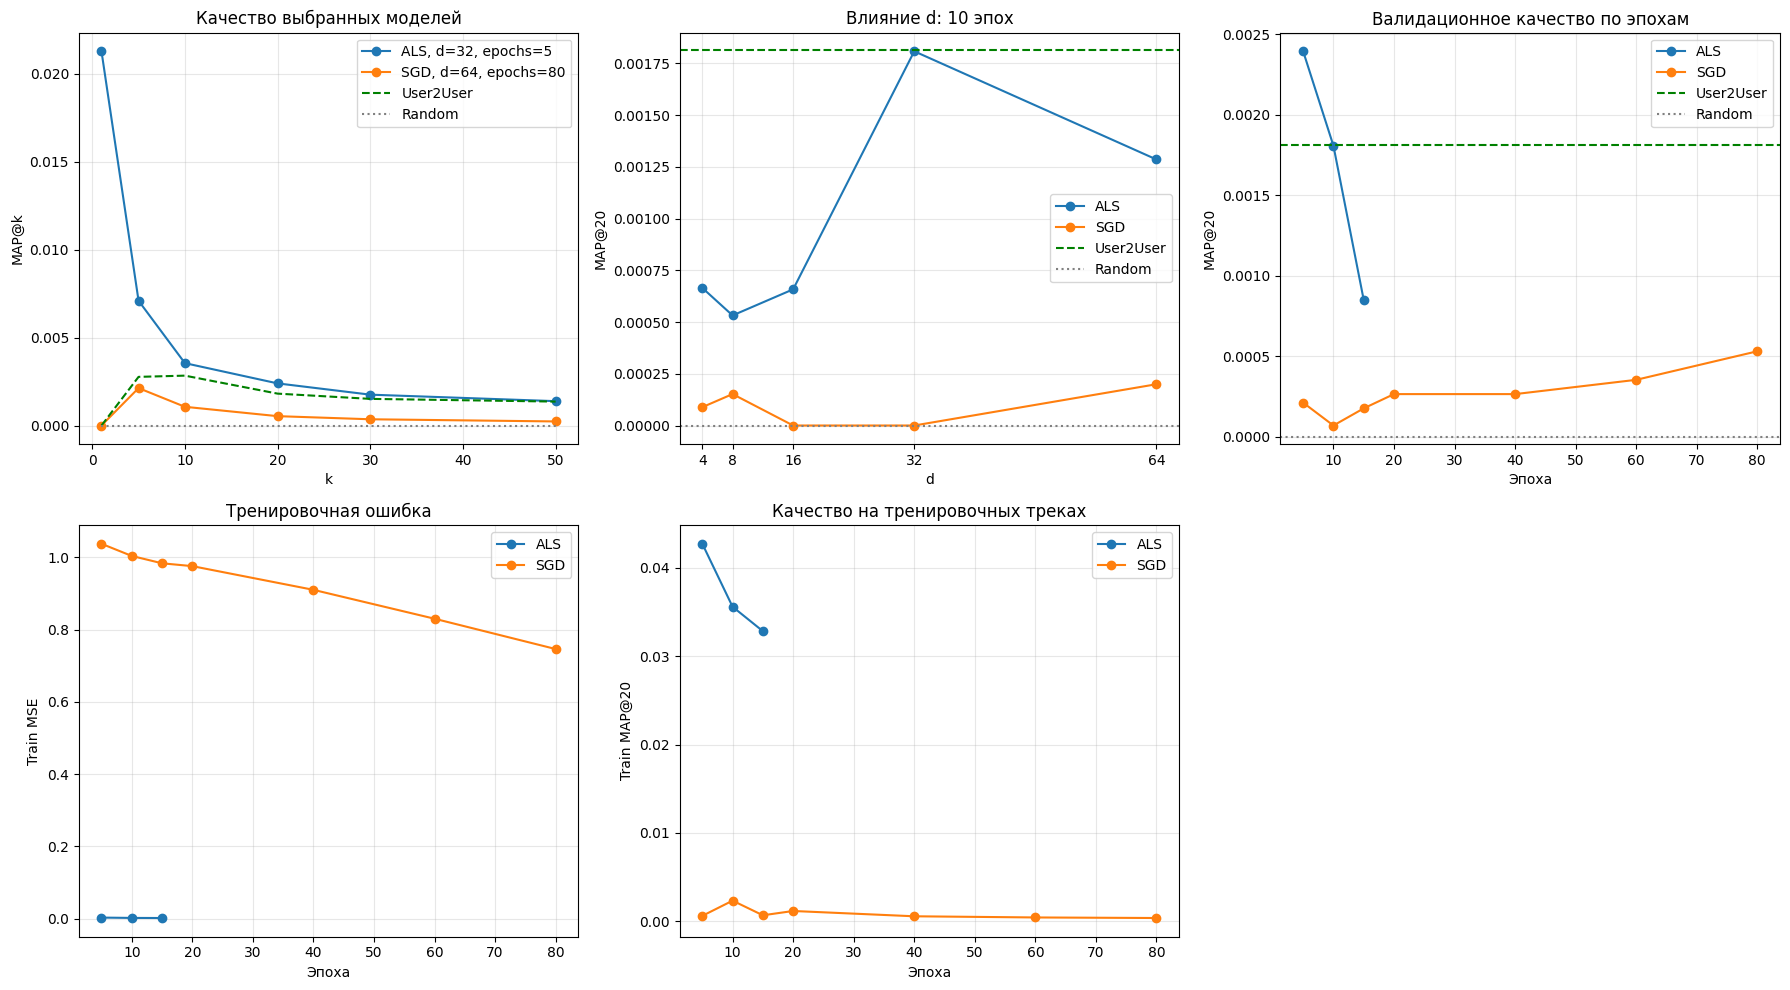

In [27]:
# 3. Выбираем лучшие конфигурации вместе с k
best_als_key = max(
    als_results, key=lambda key: als_results[key][k_idx]
)
best_sgd_key = max(
    sgd_results, key=lambda key: sgd_results[key][k_idx]
)

u2u_scores = [
    mapk(test_relevant, jaccard_preds, k=k)
    for k in k_values
]
random_scores = [
    mapk(test_relevant, random_preds, k=k)
    for k in k_values
]

models = [
    ("ALS", als_results, als_train_stats, best_als_key),
    ("SGD", sgd_results, sgd_train_stats, best_sgd_key),
]

summary = []

for name, results, train_stats, best_key in models:
    best_k = k_values[k_idx]
    best_score = results[best_key][k_idx]

    summary.append({
        "Метод": name,
        "d": best_key[0],
        "Эпохи": best_key[-1],
        "lr": best_key[1] if name == "SGD" else np.nan,
        "lambda": best_key[-2],
        "k": best_k,
        "MAP@k": best_score,
        "User2User при том же k": u2u_scores[k_idx],
        "Random при том же k": random_scores[k_idx],
        "Лучше User2User": best_score > u2u_scores[k_idx],
    })

display(pd.DataFrame(summary))


# 4. Графики
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.ravel()

for name, results, train_stats, best_key in models:
    # Качество от k для выбранной конфигурации
    axes[0].plot(
        k_values, results[best_key],
        marker="o",
        label=f"{name}, d={best_key[0]}, epochs={best_key[-1]}",
    )

    # Качество от d при одинаковых 10 эпохах и k=20.
    # Для SGD выбираем лучшие lr и lambda для каждого d.
    dim_scores = [
        max(
            scores[k_idx]
            for key, scores in results.items()
            if key[0] == d and key[-1] == 10
        )
        for d in d_values
    ]

    axes[1].plot(
        d_values, dim_scores, marker="o", label=name
    )

    # Меняем только эпоху, остальные параметры фиксируем
    epoch_keys = sorted(
        [
            key for key in results
            if key[:-1] == best_key[:-1]
        ],
        key=lambda key: key[-1],
    )
    epochs = [key[-1] for key in epoch_keys]

    axes[2].plot(
        epochs,
        [results[key][k_idx] for key in epoch_keys],
        marker="o", label=name,
    )
    axes[3].plot(
        epochs,
        [train_stats[key][0] for key in epoch_keys],
        marker="o", label=name,
    )
    axes[4].plot(
        epochs,
        [train_stats[key][1] for key in epoch_keys],
        marker="o", label=name,
    )

# Базовые методы
for name, scores, color, style in [
    ("User2User", u2u_scores, "green", "--"),
    ("Random", random_scores, "gray", ":"),
]:
    axes[0].plot(
        k_values, scores,
        label=name, color=color, linestyle=style,
    )

    for ax in axes[1:3]:
        ax.axhline(
            scores[k_idx],
            label=name, color=color, linestyle=style,
        )

settings = [
    ("Качество выбранных моделей", "k", "MAP@k"),
    ("Влияние d: 10 эпох", "d", f"MAP@{k_ref}"),
    ("Валидационное качество по эпохам", "Эпоха", f"MAP@{k_ref}"),
    ("Тренировочная ошибка", "Эпоха", "Train MSE"),
    ("Качество на тренировочных треках", "Эпоха", f"Train MAP@{k_ref}"),
]

for ax, (title, xlabel, ylabel) in zip(axes, settings):
    ax.set(title=title, xlabel=xlabel, ylabel=ylabel)
    ax.grid(alpha=0.3)
    ax.legend()

axes[1].set_xticks(d_values)
fig.delaxes(axes[5])

plt.tight_layout()
plt.show()

**Ответ:** Я бы показал ещё когда $d=128$, но там слишком долго вычисляется, а я это задание делаю уже как 5 часов. Вообще всегда за всё время пик точности был при $d=32$, потому что юзеров не так много, зачем делать такое большое латентное пространство?

Гпт предложил ещё попробовать для SGD сделать `num_epochs`=60 для того, чтобы MAP@20 $\approx 0.005$, что в 2 раза больше User2User, но я не готов на такое время вычислений.

Вообще мне больше нравится ALS, потому что он был на ОМВ, ну и для SGD нужно больше эпох и подбора параметров, чтобы сошлось

Если у вас получилось достаточно хорошее качество, то при оптимизации параметров марицы $Q$ похожим трекам стали соответствовать похожие векторы. Поэтому мы можем для любого трека найти наиболее близкие к нему в латентном пространстве и проверить степерь обученности модели вручную.

In [28]:
model = LatentFactorModel(train_ratings, dim=32, mode="als", lamb=1)
model.fit(num_iters=5)

  0%|          | 0/5 [00:00<?, ?it/s]

In [29]:
example_trackId = tracks_info[tracks_info.name == 'Выхода нет'].iloc[0].id

preds = model.Q @ model.Q[example_trackId]
preds = preds / np.sqrt((model.Q**2).sum(axis=1) + 1e-8)

track_idxs = preds.argsort()[::-1][:20]

In [30]:
similar_tracks = tracks_info.loc[track_idxs][['name', 'artists']]
similar_tracks['similarity'] = preds[track_idxs] / np.linalg.norm(model.Q[example_trackId])
similar_tracks

,name,artists,similarity
5512,Выхода нет,['Сплин'],1.000000
1831,Пачка сигарет,['КИНО'],0.787549
164,My Favourite Game,['The Cardigans'],0.735129
38809,Вояж,['Ленинград'],0.691306
5029,Jerk It Out,['Caesars'],0.689758
2527,Losing My Religion,['R.E.M.'],0.687717
4074,Creep,['Radiohead'],0.683775
30392,Сиськи,['Ленинград'],0.682167
5943,Менеджер,['Ленинград'],0.681043
10091,Look At Me Now,"['Chris Brown', 'Lil Wayne', 'Busta Rhymes']",0.672548


Ну чето похожее и получилось

**Бонус (1 балл).**

Постройте модель iALS и сравните ее качество с обучением ALS и SGD.

In [ ]:
# your code here: (￣▽￣)/♫•*¨*•.¸¸♪

### Часть 3. Второй уровень рекомендаций.

Выше мы построили простейшие модели, которые показывают не слишком высокое качество, но зато работают очень быстро. Воспользуемся ими для того, чтобы отобрать некоторое количество наиболее перспективных треков, которые мы сможем отранжировать уже более сложной моделью (в нашем случае это будет [CatBoost](https://catboost.ai/en/docs/concepts/python-reference_catboost)).

**Задание 9 (0.5 балла).**

Для каждого пользователя возьмите топ-100 рекомендованных треков от модели LFM (ALS или SGD на ваш выбор) и топ-100 от модели User2User. Это будут наши кандидаты, которые мы затем будем ранжировать бустингом.

Объедините кандидатов без дублей и уже прослушанных треков. Используйте модели, обученные на `train_ratings`, с уже выбранными параметрами.

In [34]:
lfm_model = model
u2u_model = User2User(train_ratings)

candidate_users = np.unique(np.concatenate([
    rank_train_users,
    test_users,
    final_test_users,
]))

lfm_top100 = lfm_model.get_test_recommendations(
    k=100, users=candidate_users
)
u2u_top100 = u2u_model.get_test_recommendations(
    k=100, users=candidate_users
)

candidates = {
    int(uid): np.union1d(lfm_tracks, u2u_tracks)
    for uid, lfm_tracks, u2u_tracks in zip(
        candidate_users, lfm_top100, u2u_top100
    )
}

candidates_df = pd.DataFrame(
    [
        (uid, int(track_id))
        for uid, tracks in candidates.items()
        for track_id in tracks
    ],
    columns=["userId", "trackId"],
)

display(candidates_df.head())
print(candidates_df.groupby("userId").size().describe())

,userId,trackId
0,0,94
1,0,164
2,0,189
3,0,218
4,0,388


count    235.000000
mean     185.693617
std       10.025169
min      156.000000
25%      179.000000
50%      186.000000
75%      194.000000
max      200.000000
dtype: float64


**Задание 10 (1.5 балла).**

Подготовьте датасет для обучения модели ранжирования. Он должен состоять из пар: объект, целевая переменная. Объект - это пара (user, item) и всякие дополнительные признаки на их основе. Предлагается создать набор следующих признаков, однако вы можете добавлять свои по желанию, если они вам кажутся разумными (признаки считаем на основе `train_ratings`):
 1) id пользователя
 1) id трека
 1) косинусное расстояние между эмбеддингами LFM соответствующих пользователя и трека
 1) среднее значение меры Жаккара между этим пользователем и остальными из User2User модели
 1) доля пользователей, слушавших этот трек (взять из обучающей выборки в Части 1)
 1) количество прослушанных пользователем треков (взять из обучающей выборки в Части 1)

В качестве целевой переменной возьмем бинарную метку "попал ли трек в отложенные взаимодействия пользователя".

__P.S.__ Датасет для обучения модели ранжирования строится на юзерах, которых мы в начале выделили для обучения ранкера.

In [41]:
def make_ranker_dataset(
    candidates_df,
    users,
    holdout_ratings,
    train_ratings,
    lfm_model,
    u2u_model,
):
    df = (
        candidates_df.loc[
            candidates_df["userId"].isin(users),
            ["userId", "trackId"],
        ]
        .drop_duplicates()
        .sort_values(["userId", "trackId"])
        .reset_index(drop=True)
    )

    user_ids = df["userId"].to_numpy(dtype=int)
    track_ids = df["trackId"].to_numpy(dtype=int)
    P = lfm_model.P[user_ids]
    Q = lfm_model.Q[track_ids]
    dot = (P * Q).sum(axis=1)
    norms = np.linalg.norm(P, axis=1) * np.linalg.norm(Q, axis=1)
    df["cosine_distance"] = 1 - dot / norms

    mean_jaccard = {}

    for uid in df["userId"].unique():
        similarities = np.asarray(
            u2u_model.similarity(u2u_model.R[int(uid)])
        ).ravel()

        others = similarities[np.arange(len(similarities)) != uid]
        mean_jaccard[uid] = others.mean() if len(others) else 0.0

    df["mean_jaccard"] = df["userId"].map(mean_jaccard)

    n_users = train_ratings["userId"].nunique()
    track_popularity = (
        train_ratings.groupby("trackId")["userId"].nunique()
        / n_users
    )
    df["track_popularity"] = df["trackId"].map(track_popularity)

    user_track_count = (
        train_ratings.groupby("userId")["trackId"].nunique()
    )
    df["user_track_count"] = df["userId"].map(user_track_count)

    positives = (
        holdout_ratings[["userId", "trackId"]]
        .drop_duplicates()
        .assign(target=1)
    )

    df = df.merge(
        positives,
        on=["userId", "trackId"],
        how="left",
        validate="one_to_one",
    )
    df["target"] = df["target"].fillna(0).astype("int8")

    df = df.sort_values(["userId", "trackId"]).reset_index(drop=True)

    return df.drop(columns=['target']), df['target'].to_numpy(), df['userId'].to_numpy()

In [43]:
X_train, y_train, train_group_id = make_ranker_dataset(
    candidates_df,
    rank_train_users,
    holdout_ratings,
    train_ratings,
    lfm_model,
    u2u_model,
)
X_valid, y_valid, valid_group_id = make_ranker_dataset(
    candidates_df,
    test_users,
    holdout_ratings,
    train_ratings,
    lfm_model,
    u2u_model,
)
X_test, y_test, test_group_id = make_ranker_dataset(
    candidates_df,
    final_test_users,
    holdout_ratings,
    train_ratings,
    lfm_model,
    u2u_model,
)

Как уже было сказано, для построения ранжирующей модели мы будем пользоваться библиотекой [CatBoost](https://www.youtube.com/watch?v=X1-MXdyThJ0).

Для преобразования датасета в удобный вид полезно использовать метод [`Pool`](https://catboost.ai/en/docs/concepts/python-reference_pool).

In [45]:
!pip install catboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 24.1 MB/s  0:00:04


In [46]:
import catboost

def sort_by_group(X, y, group_id):
    group_id = np.asarray(group_id)
    order = np.argsort(group_id, kind='stable')
    if hasattr(X, 'iloc'):
        X = X.iloc[order]
    elif scs.issparse(X):
        X = X.tocsr()[order]
    else:
        X = np.asarray(X)[order]
    return X, np.asarray(y)[order], group_id[order], order

# group_id == user_id here; строки каждой группы должны идти подряд
X_train, y_train, train_group_id, train_order = sort_by_group(X_train, y_train, train_group_id)
X_valid, y_valid, valid_group_id, valid_order = sort_by_group(X_valid, y_valid, valid_group_id)
X_test, y_test, test_group_id, test_order = sort_by_group(X_test, y_test, test_group_id)

train_pool = catboost.Pool(X_train, y_train, group_id=train_group_id)
valid_pool = catboost.Pool(X_valid, y_valid, group_id=valid_group_id)
test_pool = catboost.Pool(X_test, y_test, group_id=test_group_id)

__P.S.__ Обучающая выборка здесь для ранкера, а тестовая - для финальной оценки. Валидационная та же, на которой подбирали параметры предыдущих моделей. Заново делить данные не нужно

**Задание 11 (1 балл)**

Обучите `CatBoostClassifier`. С его помощью сделайте предсказания для тестовой выборки и посчитайте MAP@20. Сравните с рекомендациями моделей User2User и LFM. Учтите, что для честного сравнения необходимо пересчитать предсказания моделей на нашей новой тестовой выборке. Получилось ли улучшить результаты?

В заданиях 11–12 сначала настройте обе модели на валидации, затем сравните их на тесте. MAP@20 считайте для всех: не убирайте треки, не попавшие в кандидаты, а пользователям без рекомендаций оставьте пустой список.

In [47]:
valid_users = np.asarray(test_users)
final_users = np.asarray(final_test_users)


def get_relevant(ratings, users):
    grouped = (
        ratings.groupby("userId")["trackId"]
        .agg(list)
        .to_dict()
    )
    return [grouped.get(int(uid), []) for uid in users]


valid_relevant = get_relevant(test_ratings, valid_users)
final_relevant = get_relevant(final_test_ratings, final_users)


def recommendations_from_scores(X, scores, users, k=20):
    ranked = X[["userId", "trackId"]].copy()
    ranked["score"] = np.asarray(scores).ravel()

    ranked = (
        ranked.sort_values(
            ["userId", "score", "trackId"],
            ascending=[True, False, True],
        )
        .drop_duplicates(["userId", "trackId"])
    )

    top = ranked.groupby("userId", sort=False).head(k)
    grouped = top.groupby("userId")["trackId"].agg(list).to_dict()

    return [grouped.get(int(uid), []) for uid in users]

In [48]:
from sklearn.model_selection import ParameterGrid

def tune_catboost(kind, grid, max_trees=500, eval_period=25):
    if kind == "classifier":
        model_class = catboost.CatBoostClassifier
        loss = "Logloss"
    else:
        model_class = catboost.CatBoostRanker
        loss = "PairLogit"

    best_model = None
    best_score = -np.inf
    best_info = None
    history = []

    for trial, params in enumerate(grid, start=1):
        current = model_class(
            iterations=max_trees,
            loss_function=loss,
            random_seed=42,
            verbose=False,
            allow_writing_files=False,
            **params,
        )

        current.fit(train_pool)

        if kind == "classifier":
            stages = current.staged_predict_proba(X_valid, eval_period=eval_period)
        else:
            stages = current.staged_predict(X_valid, eval_period=eval_period)

        for step, prediction in enumerate(stages, start=1):
            n_trees = step * eval_period
            prediction = np.asarray(prediction)

            if kind == "classifier" and prediction.ndim == 2:
                scores = prediction[:, 1]
            else:
                scores = prediction

            preds = recommendations_from_scores(
                X_valid, scores, valid_users, k=20
            )
            score = mapk(valid_relevant, preds, k=20)

            history.append({
                "method": kind,
                "trial": trial,
                **params,
                "iterations": n_trees,
                "valid_MAP20": score,
            })

            if score > best_score:
                best_score = score
                best_info = {
                    **params,
                    "iterations": n_trees,
                    "valid_MAP20": score,
                }

                best_model = current.copy()
                best_model.shrink(n_trees)

        print(
            f"{kind}: {trial}/{len(grid)}, "
            f"лучший valid MAP@20={best_score:.6f}"
        )

    return best_model, best_info, pd.DataFrame(history)

In [49]:
grid = list(ParameterGrid({
    "depth": [3, 4, 5],
    "learning_rate": [0.01, 0.03, 0.1],
    "l2_leaf_reg": [1, 3, 10],
}))


classifier, classifier_info, classifier_history = tune_catboost(
    "classifier", grid
)

classifier: 1/27, лучший valid MAP@20=0.005292
classifier: 2/27, лучший valid MAP@20=0.005292
classifier: 3/27, лучший valid MAP@20=0.005292
classifier: 4/27, лучший valid MAP@20=0.005292
classifier: 5/27, лучший valid MAP@20=0.005292
classifier: 6/27, лучший valid MAP@20=0.005292
classifier: 7/27, лучший valid MAP@20=0.005292
classifier: 8/27, лучший valid MAP@20=0.005292
classifier: 9/27, лучший valid MAP@20=0.005292
classifier: 10/27, лучший valid MAP@20=0.005491
classifier: 11/27, лучший valid MAP@20=0.007520
classifier: 12/27, лучший valid MAP@20=0.007520
classifier: 13/27, лучший valid MAP@20=0.007520
classifier: 14/27, лучший valid MAP@20=0.007520
classifier: 15/27, лучший valid MAP@20=0.007520
classifier: 16/27, лучший valid MAP@20=0.007520
classifier: 17/27, лучший valid MAP@20=0.007520
classifier: 18/27, лучший valid MAP@20=0.007520
classifier: 19/27, лучший valid MAP@20=0.007520
classifier: 20/27, лучший valid MAP@20=0.007520
classifier: 21/27, лучший valid MAP@20=0.007520
c

**Задание 12 (1 балл)**

Обучите `CatBoostRanker`, выбрав подходящую функцию ранжирования из тех, которые были рассмотрены на лекции. Проделайте все те же действия, что и с `CatBoostClassifier` и сравните результаты.

In [50]:
ranker, ranker_info, ranker_history = tune_catboost(
    "ranker", grid
)

search_results = pd.concat(
    [classifier_history, ranker_history],
    ignore_index=True,
)

best_trials = (
    search_results
    .sort_values("valid_MAP20", ascending=False)
    .drop_duplicates(["method", "trial"])
)

display(best_trials.groupby("method", sort=False).head(5))

seen = (
    train_ratings.groupby("userId")["trackId"]
    .agg(list)
    .to_dict()
)


def baseline_recommendations(estimator, users, k=20):
    result = []

    for uid in users:
        ranking = np.asarray(
            estimator.recommend(int(uid)),
            dtype=int,
        ).ravel()

        unseen = ranking[
            ~np.isin(ranking, seen.get(int(uid), []))
        ]
        result.append(pd.unique(unseen)[:k].tolist())

    return result


comparison = []

for name, estimator in [
    ("User2User", u2u_model),
    ("LFM", lfm_model),
]:
    valid_preds = baseline_recommendations(estimator, valid_users)
    final_preds = baseline_recommendations(estimator, final_users)

    comparison.append({
        "Модель": name,
        "Valid MAP@20": mapk(valid_relevant, valid_preds, k=20),
        "Test MAP@20": mapk(final_relevant, final_preds, k=20),
    })

for name, estimator, info in [
    ("CatBoostClassifier", classifier, classifier_info),
    ("CatBoostRanker", ranker, ranker_info),
]:
    if X_test.empty:
        scores = np.empty(0)
    elif name == "CatBoostClassifier":
        scores = estimator.predict_proba(X_test)[:, 1]
    else:
        scores = estimator.predict(X_test)

    final_preds = recommendations_from_scores(
        X_test, scores, final_users, k=20
    )

    comparison.append({
        "Модель": name,
        "Valid MAP@20": info["valid_MAP20"],
        "Test MAP@20": mapk(final_relevant, final_preds, k=20),
    })

comparison = pd.DataFrame(comparison)
display(comparison)

ranker: 1/27, лучший valid MAP@20=0.004706
ranker: 2/27, лучший valid MAP@20=0.004706
ranker: 3/27, лучший valid MAP@20=0.004706
ranker: 4/27, лучший valid MAP@20=0.005660
ranker: 5/27, лучший valid MAP@20=0.005660
ranker: 6/27, лучший valid MAP@20=0.005660
ranker: 7/27, лучший valid MAP@20=0.005660
ranker: 8/27, лучший valid MAP@20=0.005660
ranker: 9/27, лучший valid MAP@20=0.005660
ranker: 10/27, лучший valid MAP@20=0.005660
ranker: 11/27, лучший valid MAP@20=0.005660
ranker: 12/27, лучший valid MAP@20=0.005660
ranker: 13/27, лучший valid MAP@20=0.005660
ranker: 14/27, лучший valid MAP@20=0.005660
ranker: 15/27, лучший valid MAP@20=0.005660
ranker: 16/27, лучший valid MAP@20=0.005660
ranker: 17/27, лучший valid MAP@20=0.005660
ranker: 18/27, лучший valid MAP@20=0.005660
ranker: 19/27, лучший valid MAP@20=0.005660
ranker: 20/27, лучший valid MAP@20=0.005660
ranker: 21/27, лучший valid MAP@20=0.005660
ranker: 22/27, лучший valid MAP@20=0.005660
ranker: 23/27, лучший valid MAP@20=0.0056

,method,trial,depth,l2_leaf_reg,learning_rate,iterations,valid_MAP20
200,classifier,11,4,1,0.03,25,0.007520
260,classifier,14,4,3,0.03,25,0.007296
321,classifier,17,4,10,0.03,50,0.006107
600,ranker,4,3,3,0.01,25,0.005660
183,classifier,10,4,1,0.01,100,0.005491
243,classifier,13,4,3,0.01,100,0.005343
660,ranker,7,3,10,0.01,25,0.005181
680,ranker,8,3,10,0.03,25,0.004982
540,ranker,1,3,1,0.01,25,0.004706
781,ranker,13,4,3,0.01,50,0.004473


,Модель,Valid MAP@20,Test MAP@20
0,User2User,0.001813,0.000240
1,LFM,0.000226,0.001228
2,CatBoostClassifier,0.007520,0.006699
3,CatBoostRanker,0.005660,0.006343


**Ответ:** CatBoostClassifier лучше всех был по качеству. CatBoost оказался лучше, потому что данных было больше, чем у User2User и LFM. Также бустинг это нелинейная модель, скорее всего по этому и лучше было по качеству.

# Использование ИИ

Я использовал ChatGPT 6.1 Sol:
  1. в задаче 5 для рисования графика
  2. в задаче 8 для подбора параметров и рисования графика
  3. Трейнлуп и сравнение в заданиях 11 и 12